In [1]:
from pathlib import Path
import os 

import numpy as np
import scanpy as sc 
import matplotlib.pyplot as plt 
import seaborn as sns

from dotenv import dotenv_values

In [2]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Fig_02"
os.makedirs(OUTDIR, exist_ok=True)

OBJECTS_DIR = DATADIR / "9_objects"
SC_ADATA_FP = OBJECTS_DIR / "singlecell" / "hypomap3d_singlecell_control.h5ad" 

In [3]:
adata_sc = sc.read_h5ad(SC_ADATA_FP, backed="r")

In [4]:
scattersize = 0.05

## L2

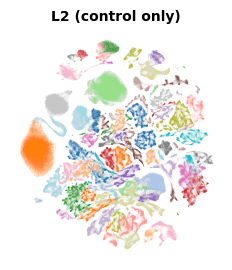

In [5]:

# Create a high-DPI figure and axis
fig, ax = plt.subplots(figsize=(3,3), ) 

# Generate a large palette
n_categories = adata_sc.obs['L2_descr'].nunique()
palette = sns.color_palette("tab20", n_categories)  # or "husl", "tab10", "hsv", "Spectral"

# Randomize (shuffle) color order
rng = np.random.default_rng(seed=42)  # optional: set seed for reproducibility
palette = rng.permutation(palette).tolist()

# Pass the axis to Scanpy
sc.pl.umap(adata_sc, color="L2_descr", ax=ax, s=scattersize, show=False, legend_loc="none", palette=palette,
    )

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("L2 (control only)", fontsize=10, fontweight="bold")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')

fig.canvas.draw()

plt.savefig(OUTDIR /  "umap_L2_C_tab20.pdf", format="pdf", dpi=300, bbox_inches="tight") 

## Region umbrella

In [6]:
umbrella_colors = {'Anterior HY': '#1f77b4',
 'Basal HY': 'saddlebrown',
 'Dorsal-lateral HY': '#ff7f0e',
 'Extra-hypothalamic': 'red',
 'HY (Gnrh1 neurons)': 'purple',
 'Mammillary regions': '#98df8a',
 'Non-neuronal cells': 'lightgrey',
 'PVH region': '#ff9896',
 'Posterior HY': '#9467bd',
 'Preoptic HY': '#c5b0d5',
 'SCH': 'cyan',
 'ZI/Subthalamic': '#c49c94'}

In [7]:
adata_sc.obs["region"] = adata_sc.obs.L3_descr.apply(lambda x: x.split(" ")[1] if "NN" not in x else "NN")

adata_sc.obs["region_umbrella"] = adata_sc.obs.region.astype(str).copy() 

umbrella_dict = {
    "Mammillary regions": ["MMl", "MMm", "MMme","TMv", "PMv", "SUM", "LM", "PMd"],
    "PVH region": ["PVH", "PVHd", "PVH-SO"],
    "Basal HY": ["ARH", "VMH", "TU"],
    "Dorsal-lateral HY": ["LHA", "DMH"],
    "Anterior HY": ["AHN", "SBPV", "PVi",],
    "Preoptic HY": ["LPO", "MEPO", "MPO", "MPN", "PS", "PVpo", "AVPV" ],
    "ZI/Subthalamic": ["PSTN", "STN", "ZI"],
    "Extra-hypothalamic": ["BST", "CP", "LSr", "LSv", "MB", "MEA", "NDB", "RT", "VAL", "VPM", "SI", "MS"],
    "Posterior HY": ["PH", "PVp", ],
    "HY (Gnrh1 neurons)": ["HY"]
}

for k, v in umbrella_dict.items():
    adata_sc.obs.loc[adata_sc.obs.region_umbrella.isin(v), "region_umbrella"] = k

adata_sc.obs.loc[adata_sc.obs.region_umbrella == "NN", "region_umbrella"] = "Non-neuronal cells"

adata_sc.obs["region_umbrella"].unique()

array(['Basal HY', 'Anterior HY', 'Dorsal-lateral HY',
       'Extra-hypothalamic', 'Preoptic HY', 'Mammillary regions',
       'Posterior HY', 'PVH region', 'ZI/Subthalamic', 'SCH',
       'HY (Gnrh1 neurons)', 'Non-neuronal cells'], dtype=object)

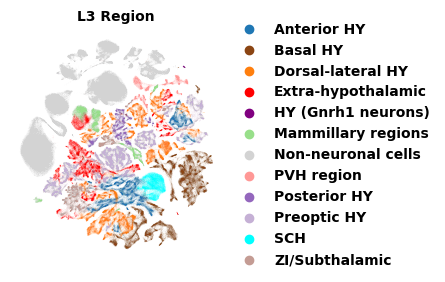

In [8]:

# Create a high-DPI figure and axis
fig, ax = plt.subplots(figsize=(3,3), ) 

# Pass the axis to Scanpy
sc.pl.umap(adata_sc, color="region_umbrella", ax=ax, s=scattersize, 
    show=False, palette=umbrella_colors,
    )

# Rasterize only the scatter points (not text)
for coll in ax.collections:
    coll.set_rasterized(True)

# Customize: remove title, borders, ticks, labels
ax.set_title("L3 Region", fontsize=10, fontweight="bold")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')

fig.canvas.draw()

legend = ax.get_legend()

if legend is not None:
    for text in legend.get_texts():
        text.set_fontweight("bold")

plt.savefig(OUTDIR /  "umap_L3_region_umbrella.pdf", format="pdf", dpi=300, bbox_inches="tight") 